# RQ2 — ESRS Domain Adaptation: Context Injection Ablation Study

**Research Question:** *To what extent does explicitly injecting structured ESRS regulatory requirements into the generation prompt improve compliance assessment accuracy and answer faithfulness, compared to relying on the LLM's general pretraining knowledge of ESRS?*

---

## Experimental Design

This notebook implements a controlled ablation study with **two conditions**, both using the best retrieval configuration identified in RQ1:

| Condition | Retrieval | ESRS Context | What it tests |
|---|---|---|---|
| **Full system** | Best RQ1 config | Injected from ESRS JSON | LLM uses retrieved passages + explicit ESRS requirements |
| **No ESRS context** | Best RQ1 config | Empty string | LLM relies on retrieved passages + parametric knowledge only |

**Dataset:** 12 questions × 17 companies = 204 samples per condition → **408 total generation calls**

**Evaluation:** Four deterministic metrics (no LLM judge):
1. **Compliance accuracy** — exact match of predicted vs gold fulfillment level (Low/Medium/High)
2. **Off-by-one accuracy** — prediction within one ordinal step of gold label
3. **Token F1** — lexical overlap between generated and gold answer
4. **Faithfulness score** — fraction of generated claims supported by retrieved passages

## 1. Setup and Imports

In [1]:
import sys
import os
from pathlib import Path

# Ensure project root is on the Python path
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

# Explicitly load .env from project root so the Jupyter kernel picks it up
# regardless of its working directory.
from dotenv import load_dotenv
load_dotenv(PROJECT_ROOT / ".env", override=True)

import json
import warnings
import logging
from collections import defaultdict
from dataclasses import asdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

# Suppress noisy warnings for clean notebook output
warnings.filterwarnings("ignore", category=FutureWarning)
logging.basicConfig(level=logging.WARNING)

# Plotting defaults for thesis figures
plt.rcParams.update({
    "figure.figsize": (10, 6),
    "figure.dpi": 120,
    "font.size": 11,
    "axes.titlesize": 13,
    "axes.labelsize": 11,
    "legend.fontsize": 10,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
})

print(f"Project root: {PROJECT_ROOT}")
print(f"Python: {sys.version.split()[0]}")

python-dotenv could not parse statement starting at line 1
python-dotenv could not parse statement starting at line 10
python-dotenv could not parse statement starting at line 11
python-dotenv could not parse statement starting at line 26


Project root: /Users/sinahaghgoo/Library/CloudStorage/OneDrive-Persönlich/Master Thesis/Thesis Coding Part/ESRS-Regulation-Bot
Python: 3.12.9


## 2. Load Best RQ1 Pipeline Configuration

RQ2 reuses the winning retrieval setup from RQ1 as a fixed input. Both experimental conditions share identical retrieval — the only variable is whether ESRS regulatory context is injected into the generation prompt.

In [2]:
from rag.config.settings import load_best_pipeline_config, GOLDEN_STANDARD_PATH

best_config = load_best_pipeline_config()
pipeline_name = best_config.pop("_best_pipeline_name", "unknown")
selection_reason = best_config.pop("_selection_reason", "")

print(f"Best RQ1 pipeline: {pipeline_name}")
print(f"Selection reason:  {selection_reason}")
print(f"\nConfiguration:")
for k, v in best_config.items():
    print(f"  {k}: {v}")

Best RQ1 pipeline: fixed_1024_hybrid_rerank
Selection reason:  Highest recall@15 (0.9620) in RQ1.

Configuration:
  chunk_strategy: fixed
  chunk_size: 1024
  retrieval_method: hybrid_rerank
  chunk_overlap_ratio: 0.125
  top_k: 15
  rrf_k: 60
  rerank_model: cross-encoder/ms-marco-MiniLM-L-6-v2


## 3. Load Golden Standard and ESRS Standards

In [3]:
from rag.data.loaders import load_golden_samples, load_reports
from rag.generation.esrs_context import load_esrs_standards, extract_esrs_context

# Load evaluation samples
samples = load_golden_samples()
print(f"Golden Standard: {len(samples)} evaluation samples")

# Load raw golden standard for ground-truth answers
raw_golden = json.loads(GOLDEN_STANDARD_PATH.read_text(encoding="utf-8"))
golden_lookup = {}
for q in raw_golden["questions"]:
    for pc in q["per_company"]:
        golden_lookup[(q["id"], pc["company"])] = {
            "question": q["question"],
            "esrs_standard": q.get("esrs_standard", ""),
            "ground_truth_answer": pc.get("ground_truth_answer", ""),
            "fulfillment_level": pc.get("fulfillment_level", ""),
        }

# Verify coverage
levels = [v["fulfillment_level"] for v in golden_lookup.values()]
from collections import Counter
level_dist = Counter(levels)
print(f"Fulfillment level distribution: {dict(level_dist)}")

# Load ESRS standards
esrs_standards = load_esrs_standards()
print(f"\nLoaded {len(esrs_standards)} ESRS standards: {sorted(esrs_standards.keys())}")

# Show context sizes per standard
print(f"\nESRS context sizes (characters):")
for std_id in sorted(esrs_standards.keys()):
    ctx = extract_esrs_context(std_id, esrs_standards)
    print(f"  {std_id}: {len(ctx):,} chars")

Golden Standard: 204 evaluation samples
Fulfillment level distribution: {'High': 145, 'Low': 26, 'Medium': 33}

Loaded 12 ESRS standards: ['ESRS 1', 'ESRS 2', 'ESRS E1', 'ESRS E2', 'ESRS E3', 'ESRS E4', 'ESRS E5', 'ESRS G1', 'ESRS S1', 'ESRS S2', 'ESRS S3', 'ESRS S4']

ESRS context sizes (characters):
  ESRS 1: 14,073 chars
  ESRS 2: 63,896 chars
  ESRS E1: 51,588 chars
  ESRS E2: 21,098 chars
  ESRS E3: 21,028 chars
  ESRS E4: 35,426 chars
  ESRS E5: 25,569 chars
  ESRS G1: 19,159 chars
  ESRS S1: 64,668 chars
  ESRS S2: 35,294 chars
  ESRS S3: 32,381 chars
  ESRS S4: 30,927 chars


## 4. Initialize Retrieval Pipeline

We build the retriever once using the best RQ1 config. Retrieved passages are cached and shared across both conditions to ensure the only experimental variable is ESRS context injection.

In [4]:
from rag.config.settings import PipelineConfig, ensure_dirs
from rag.chunking.strategies import build_chunks_for_config
from rag.indexing.embedder import EmbeddingService
from rag.indexing.qdrant_index import QdrantChunkIndex
from rag.retrieval.methods import Retriever

ensure_dirs()

# Create RQ2 output directory for plots and results
rq2_output_dir = PROJECT_ROOT / "data" / "artifacts" / "evaluation_results" / "rq2"
rq2_output_dir.mkdir(parents=True, exist_ok=True)

# Load reports
reports = load_reports()
print(f"Loaded {len(reports)} company reports")

# Build pipeline config
pipe_config = PipelineConfig(
    chunk_strategy=best_config["chunk_strategy"],
    chunk_size=int(best_config["chunk_size"]),
    retrieval_method=best_config["retrieval_method"],
    chunk_overlap_ratio=float(best_config.get("chunk_overlap_ratio", 0.125)),
    top_k=int(best_config.get("top_k", 15)),
    rrf_k=int(best_config.get("rrf_k", 60)),
)
print(f"Pipeline config: {pipe_config.config_id}")

# Build chunks
chunks, chunk_stats = build_chunks_for_config(reports, pipe_config)
print(f"Built {len(chunks)} chunks")

# Initialize embedding service and Qdrant
embedder = EmbeddingService(require_openai=True, load_cache=True)
qdrant = QdrantChunkIndex(dims=embedder.dims)

Loaded 17 company reports
Pipeline config: fixed_1024_hybrid_rerank
Built 2617 chunks


In [5]:
# Ensure Qdrant collection exists
collection = qdrant.collection_name(pipe_config.chunk_strategy, pipe_config.chunk_size)
existing = qdrant.collection_point_count(collection)

if existing > 0:
    print(f"Qdrant collection '{collection}' has {existing} vectors — reusing")
else:
    print(f"Building Qdrant collection '{collection}' ({len(chunks)} chunks)...")
    vectors = embedder.embed_texts([c.retrieval_text for c in chunks])
    qdrant.recreate_collection(collection)
    qdrant.upsert_chunks(collection, chunks, vectors)
    print("Done.")

# Build retriever
retriever = Retriever(
    chunks=chunks,
    config=pipe_config,
    embedder=embedder,
    qdrant=qdrant,
)
print(f"Retriever ready: {pipe_config.retrieval_method}")

Qdrant collection 'rq1_esrs_418550d6ec_fixed_1024' has 2617 vectors — reusing
Retriever ready: hybrid_rerank


## 5. Run Both Experimental Conditions

For each of the 204 golden-standard samples, we:
1. Retrieve the top-15 passages (shared across conditions)
2. Generate an answer under each condition (with/without ESRS context)
3. Evaluate against the golden standard

All generation calls are cached deterministically — re-runs are free.

In [6]:
from rag.generation.generator import generate_answer
from rag.evaluation.rq2_metrics import evaluate_sample, RQ2SampleResult

CONDITIONS = ["full_system", "no_esrs_context"]
results_by_condition = {c: [] for c in CONDITIONS}
retrieval_cache = {}  # (question, company) -> list[RetrievalHit]

n_total = len(samples)
n_errors = 0

print(f"Running RQ2 experiment: {n_total} samples × 2 conditions = {n_total * 2} generation calls")
print("=" * 70)

for idx, sample in enumerate(samples):
    qid = sample.question_id
    company = sample.company
    esrs_std = sample.esrs_standard

    # Look up golden data
    gold_data = golden_lookup.get((qid, company))
    if gold_data is None or not gold_data["fulfillment_level"]:
        continue

    gold_answer = gold_data["ground_truth_answer"]
    gold_level = gold_data["fulfillment_level"]

    # Retrieve passages (cached, shared across conditions)
    cache_key = (sample.question, company)
    if cache_key not in retrieval_cache:
        retrieval_cache[cache_key] = retriever.retrieve(
            query=sample.question, company=company, top_k=15
        )
    hits = retrieval_cache[cache_key]
    passages = [h.chunk.text for h in hits]

    # Extract ESRS context
    esrs_context = extract_esrs_context(esrs_std, esrs_standards, sample.question)

    # Run both conditions
    for condition in CONDITIONS:
        ctx = esrs_context if condition == "full_system" else ""
        try:
            gen_result = generate_answer(
                question=sample.question,
                company=company,
                retrieved_passages=passages,
                esrs_context=ctx,
                condition=condition,
                use_cache=True,
            )
        except Exception as exc:
            n_errors += 1
            print(f"  ERROR [{condition}] ({qid}, {company}): {exc}")
            continue

        eval_result = evaluate_sample(
            question_id=qid,
            company=company,
            esrs_standard=esrs_std,
            condition=condition,
            predicted_level=gen_result["compliance_level"],
            gold_level=gold_level,
            generated_answer=gen_result["answer"],
            gold_answer=gold_answer,
            retrieved_passages=passages,
        )
        results_by_condition[condition].append(eval_result)

    if (idx + 1) % 20 == 0 or idx == 0:
        print(f"  Processed {idx + 1}/{n_total} samples")

print(f"\nCompleted. Errors: {n_errors}")
for c in CONDITIONS:
    print(f"  {c}: {len(results_by_condition[c])} results")

Running RQ2 experiment: 204 samples × 2 conditions = 408 generation calls
  Processed 1/204 samples
  Processed 20/204 samples
  Processed 40/204 samples
  Processed 60/204 samples
  Processed 80/204 samples
  Processed 100/204 samples
  Processed 120/204 samples
  Processed 140/204 samples
  Processed 160/204 samples
  Processed 180/204 samples
  Processed 200/204 samples

Completed. Errors: 0
  full_system: 204 results
  no_esrs_context: 204 results


## 6. Sanity Checks and Diagnostics

Before analyzing results, we verify data integrity: correct sample counts, valid compliance levels in all predictions, and balanced coverage across standards and companies.

In [7]:
# Sanity check: sample counts
for condition in CONDITIONS:
    n = len(results_by_condition[condition])
    print(f"{condition}: {n} samples (expected: {n_total})")
    
    # Check for missing/invalid compliance levels
    levels_pred = [r.predicted_level for r in results_by_condition[condition]]
    invalid = [l for l in levels_pred if l not in ("Low", "Medium", "High")]
    if invalid:
        print(f"  WARNING: {len(invalid)} invalid predicted levels: {set(invalid)}")
    else:
        print(f"  All predicted levels valid")
    
    # Distribution of predicted levels
    pred_dist = Counter(levels_pred)
    print(f"  Predicted distribution: {dict(pred_dist)}")

# Gold level distribution (for reference)
gold_levels = [r.gold_level for r in results_by_condition["full_system"]]
print(f"\nGold level distribution: {dict(Counter(gold_levels))}")

full_system: 204 samples (expected: 204)
  All predicted levels valid
  Predicted distribution: {'Medium': 142, 'High': 37, 'Low': 25}
no_esrs_context: 204 samples (expected: 204)
  All predicted levels valid
  Predicted distribution: {'Medium': 139, 'High': 43, 'Low': 22}

Gold level distribution: {'High': 145, 'Low': 26, 'Medium': 33}


In [8]:
# Check coverage: every ESRS standard and every company should be present
for condition in CONDITIONS:
    standards_seen = set(r.esrs_standard for r in results_by_condition[condition])
    companies_seen = set(r.company for r in results_by_condition[condition])
    print(f"\n{condition}:")
    print(f"  ESRS standards: {len(standards_seen)} (expected: 12)")
    print(f"  Companies: {len(companies_seen)} (expected: 17)")
    
    # Check per-standard sample counts
    std_counts = Counter(r.esrs_standard for r in results_by_condition[condition])
    for std in sorted(std_counts.keys()):
        count = std_counts[std]
        marker = "" if count == 17 else f" ← UNEXPECTED (expected 17)"
        print(f"    {std}: {count} samples{marker}")


full_system:
  ESRS standards: 12 (expected: 12)
  Companies: 17 (expected: 17)
    ESRS 1: 17 samples
    ESRS 2: 17 samples
    ESRS E1: 17 samples
    ESRS E2: 17 samples
    ESRS E3: 17 samples
    ESRS E4: 17 samples
    ESRS E5: 17 samples
    ESRS G1: 17 samples
    ESRS S1: 17 samples
    ESRS S2: 17 samples
    ESRS S3: 17 samples
    ESRS S4: 17 samples

no_esrs_context:
  ESRS standards: 12 (expected: 12)
  Companies: 17 (expected: 17)
    ESRS 1: 17 samples
    ESRS 2: 17 samples
    ESRS E1: 17 samples
    ESRS E2: 17 samples
    ESRS E3: 17 samples
    ESRS E4: 17 samples
    ESRS E5: 17 samples
    ESRS G1: 17 samples
    ESRS S1: 17 samples
    ESRS S2: 17 samples
    ESRS S3: 17 samples
    ESRS S4: 17 samples


## 7. Aggregate Metric Comparison

The central comparison of RQ2: does explicit ESRS context injection improve compliance assessment and answer quality?

In [9]:
from rag.evaluation.rq2_metrics import aggregate_results

aggregates = {}
for condition in CONDITIONS:
    aggregates[condition] = aggregate_results(
        results_by_condition[condition], condition
    )

# Build comparison table
metrics_table = []
for metric_name, attr_name in [
    ("Compliance Accuracy", "compliance_accuracy"),
    ("Off-by-One Accuracy", "off_by_one_accuracy"),
    ("Token F1", "token_f1"),
    ("Token Precision", "token_precision"),
    ("Token Recall", "token_recall"),
    ("Faithfulness", "faithfulness"),
]:
    full_val = getattr(aggregates["full_system"], attr_name)
    no_esrs_val = getattr(aggregates["no_esrs_context"], attr_name)
    delta = full_val - no_esrs_val
    
    # Get std if available
    std_attr = f"{attr_name}_std"
    full_std = getattr(aggregates["full_system"], std_attr, None)
    no_esrs_std = getattr(aggregates["no_esrs_context"], std_attr, None)
    
    row = {
        "Metric": metric_name,
        "Full System": f"{full_val:.4f}" + (f" ± {full_std:.4f}" if full_std else ""),
        "No ESRS Context": f"{no_esrs_val:.4f}" + (f" ± {no_esrs_std:.4f}" if no_esrs_std else ""),
        "Δ (Full - No ESRS)": f"{delta:+.4f}",
        "Δ_raw": delta,
    }
    metrics_table.append(row)

df_metrics = pd.DataFrame(metrics_table)
print("\n" + "=" * 80)
print("RQ2 AGGREGATE RESULTS")
print("=" * 80)
print(df_metrics[["Metric", "Full System", "No ESRS Context", "Δ (Full - No ESRS)"]].to_string(index=False))


RQ2 AGGREGATE RESULTS
             Metric     Full System No ESRS Context Δ (Full - No ESRS)
Compliance Accuracy 0.4069 ± 0.4925 0.4216 ± 0.4950            -0.0147
Off-by-One Accuracy 0.9902 ± 0.0988 0.9902 ± 0.0988            +0.0000
           Token F1 0.2838 ± 0.1023 0.3400 ± 0.1036            -0.0562
    Token Precision          0.1892          0.2376            -0.0483
       Token Recall          0.7637          0.7335            +0.0302
       Faithfulness 0.9998 ± 0.0023          1.0000            -0.0002


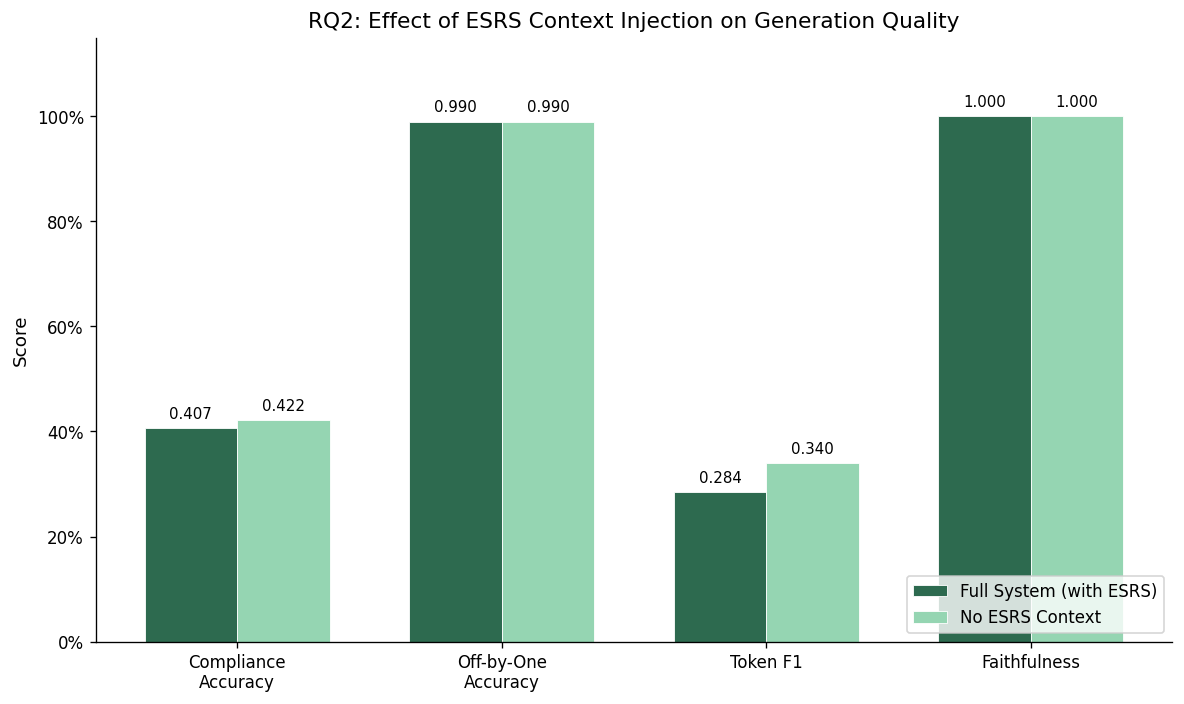

In [10]:
# Visualize aggregate comparison
metric_names = ["Compliance\nAccuracy", "Off-by-One\nAccuracy", "Token F1", "Faithfulness"]
full_vals = [
    aggregates["full_system"].compliance_accuracy,
    aggregates["full_system"].off_by_one_accuracy,
    aggregates["full_system"].token_f1,
    aggregates["full_system"].faithfulness,
]
no_esrs_vals = [
    aggregates["no_esrs_context"].compliance_accuracy,
    aggregates["no_esrs_context"].off_by_one_accuracy,
    aggregates["no_esrs_context"].token_f1,
    aggregates["no_esrs_context"].faithfulness,
]

x = np.arange(len(metric_names))
width = 0.35

fig, ax = plt.subplots(figsize=(10, 6))
bars1 = ax.bar(x - width/2, full_vals, width, label="Full System (with ESRS)",
               color="#2D6A4F", edgecolor="white", linewidth=0.5)
bars2 = ax.bar(x + width/2, no_esrs_vals, width, label="No ESRS Context",
               color="#95D5B2", edgecolor="white", linewidth=0.5)

# Add value labels on bars
for bars in [bars1, bars2]:
    for bar in bars:
        height = bar.get_height()
        ax.annotate(f"{height:.3f}",
                    xy=(bar.get_x() + bar.get_width()/2, height),
                    xytext=(0, 4), textcoords="offset points",
                    ha="center", va="bottom", fontsize=9)

ax.set_ylabel("Score")
ax.set_title("RQ2: Effect of ESRS Context Injection on Generation Quality")
ax.set_xticks(x)
ax.set_xticklabels(metric_names)
ax.legend(loc="lower right")
ax.set_ylim(0, 1.15)
ax.yaxis.set_major_formatter(mticker.PercentFormatter(xmax=1.0))
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
plt.tight_layout()
plt.savefig(PROJECT_ROOT / "data" / "artifacts" / "evaluation_results" / "rq2" / "rq2_aggregate_comparison.png",
            dpi=150, bbox_inches="tight")
plt.show()

## 8. Per-ESRS-Standard Breakdown

Analyze which of the 12 ESRS standards benefit most from explicit regulatory context injection. This helps identify whether the effect is uniform across topics or concentrated in specific standards.

In [11]:
# Build per-standard comparison table
per_std_rows = []
all_standards = sorted(set(
    r.esrs_standard for r in results_by_condition["full_system"]
))

for std in all_standards:
    full_std_data = aggregates["full_system"].per_standard.get(std, {})
    no_esrs_std_data = aggregates["no_esrs_context"].per_standard.get(std, {})
    
    full_acc = full_std_data.get("compliance_accuracy", 0)
    no_esrs_acc = no_esrs_std_data.get("compliance_accuracy", 0)
    delta_acc = full_acc - no_esrs_acc
    
    full_f1 = full_std_data.get("token_f1", 0)
    no_esrs_f1 = no_esrs_std_data.get("token_f1", 0)
    delta_f1 = full_f1 - no_esrs_f1
    
    full_faith = full_std_data.get("faithfulness", 0)
    no_esrs_faith = no_esrs_std_data.get("faithfulness", 0)
    delta_faith = full_faith - no_esrs_faith
    
    per_std_rows.append({
        "ESRS Standard": std,
        "N": full_std_data.get("n_samples", 0),
        "Compl. Acc (Full)": f"{full_acc:.3f}",
        "Compl. Acc (No ESRS)": f"{no_esrs_acc:.3f}",
        "Δ Compl. Acc": f"{delta_acc:+.3f}",
        "Token F1 (Full)": f"{full_f1:.3f}",
        "Token F1 (No ESRS)": f"{no_esrs_f1:.3f}",
        "Δ Token F1": f"{delta_f1:+.3f}",
        "Faith. (Full)": f"{full_faith:.3f}",
        "Faith. (No ESRS)": f"{no_esrs_faith:.3f}",
        "Δ Faith.": f"{delta_faith:+.3f}",
        "_delta_acc": delta_acc,
    })

df_per_std = pd.DataFrame(per_std_rows)
print("\nPer-ESRS-Standard Compliance Accuracy Comparison:")
print(df_per_std[["ESRS Standard", "N", "Compl. Acc (Full)", "Compl. Acc (No ESRS)",
                   "Δ Compl. Acc", "Token F1 (Full)", "Token F1 (No ESRS)", "Δ Token F1"]].to_string(index=False))


Per-ESRS-Standard Compliance Accuracy Comparison:
ESRS Standard  N Compl. Acc (Full) Compl. Acc (No ESRS) Δ Compl. Acc Token F1 (Full) Token F1 (No ESRS) Δ Token F1
       ESRS 1 17             0.176                0.118       +0.059           0.289              0.343     -0.055
       ESRS 2 17             0.412                0.294       +0.118           0.340              0.432     -0.092
      ESRS E1 17             0.294                0.471       -0.176           0.327              0.402     -0.076
      ESRS E2 17             0.353                0.294       +0.059           0.197              0.284     -0.087
      ESRS E3 17             0.471                0.588       -0.118           0.418              0.452     -0.034
      ESRS E4 17             0.235                0.294       -0.059           0.278              0.326     -0.047
      ESRS E5 17             0.824                0.824       +0.000           0.365              0.392     -0.027
      ESRS G1 17             

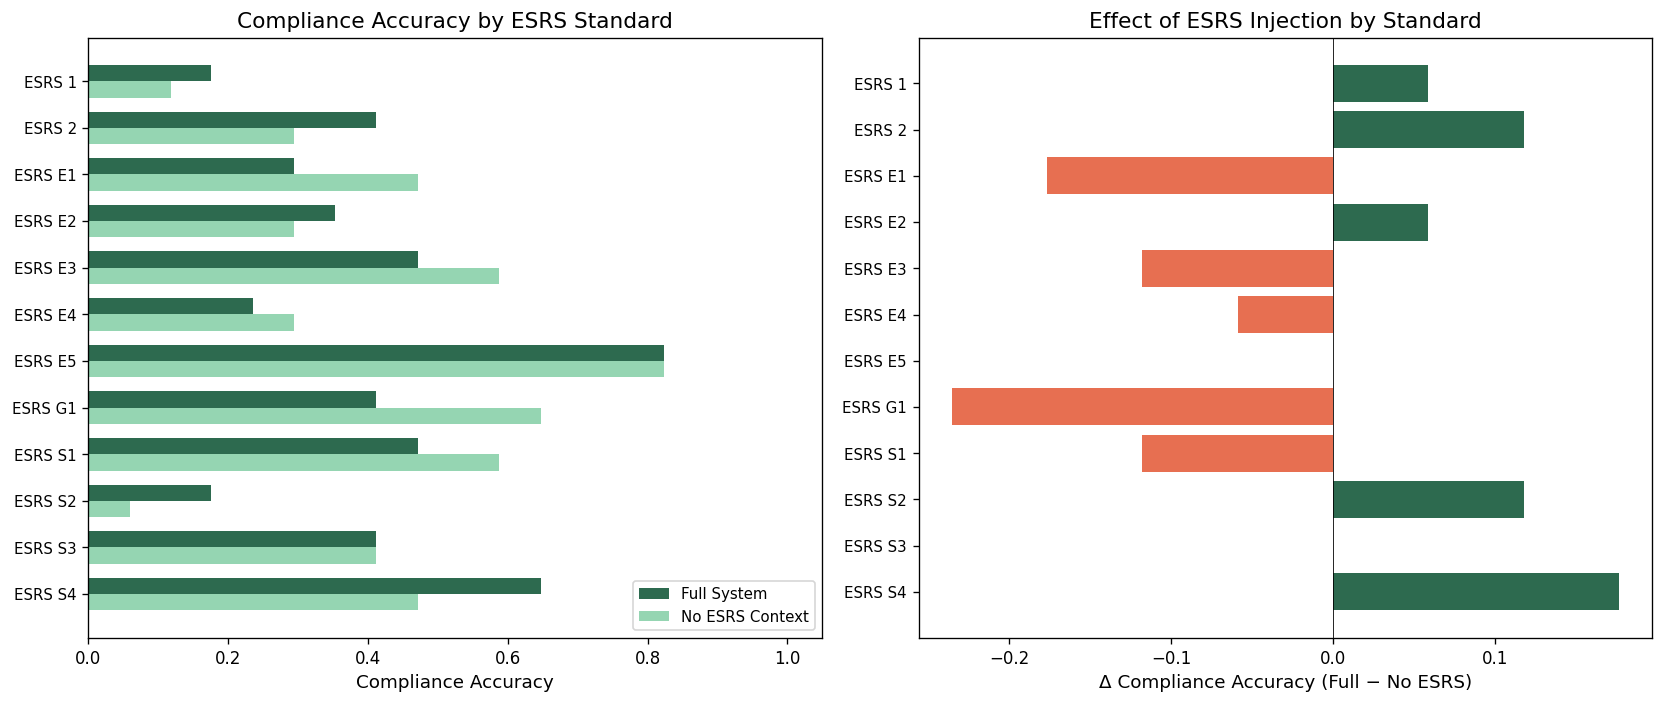

In [12]:
# Visualize per-standard compliance accuracy delta
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Left: Compliance accuracy by standard
ax = axes[0]
standards = df_per_std["ESRS Standard"].tolist()
full_accs = [float(v) for v in df_per_std["Compl. Acc (Full)"]]
no_esrs_accs = [float(v) for v in df_per_std["Compl. Acc (No ESRS)"]]

x = np.arange(len(standards))
width = 0.35
ax.barh(x - width/2, full_accs, width, label="Full System", color="#2D6A4F")
ax.barh(x + width/2, no_esrs_accs, width, label="No ESRS Context", color="#95D5B2")
ax.set_yticks(x)
ax.set_yticklabels(standards, fontsize=9)
ax.set_xlabel("Compliance Accuracy")
ax.set_title("Compliance Accuracy by ESRS Standard")
ax.legend(loc="lower right", fontsize=9)
ax.set_xlim(0, 1.05)
ax.invert_yaxis()

# Right: Delta (improvement from ESRS injection)
ax = axes[1]
deltas = df_per_std["_delta_acc"].tolist()
colors = ["#2D6A4F" if d > 0 else ("#E76F51" if d < 0 else "#999999") for d in deltas]
ax.barh(x, deltas, color=colors)
ax.set_yticks(x)
ax.set_yticklabels(standards, fontsize=9)
ax.set_xlabel("Δ Compliance Accuracy (Full − No ESRS)")
ax.set_title("Effect of ESRS Injection by Standard")
ax.axvline(x=0, color="black", linewidth=0.5)
ax.invert_yaxis()

plt.tight_layout()
plt.savefig(PROJECT_ROOT / "data" / "artifacts" / "evaluation_results" / "rq2" / "rq2_per_standard.png",
            dpi=150, bbox_inches="tight")
plt.show()

## 9. Per-Company Analysis

Do the same companies systematically benefit from ESRS injection, or is the effect uniform across the 17-company dataset?

In [13]:
# Build per-company comparison
per_co_rows = []
all_companies = sorted(set(
    r.company for r in results_by_condition["full_system"]
))

for co in all_companies:
    full_co = aggregates["full_system"].per_company.get(co, {})
    no_esrs_co = aggregates["no_esrs_context"].per_company.get(co, {})
    
    full_acc = full_co.get("compliance_accuracy", 0)
    no_esrs_acc = no_esrs_co.get("compliance_accuracy", 0)
    delta = full_acc - no_esrs_acc
    
    full_f1 = full_co.get("token_f1", 0)
    no_esrs_f1 = no_esrs_co.get("token_f1", 0)
    
    per_co_rows.append({
        "Company": co,
        "N": full_co.get("n_samples", 0),
        "Compl. Acc (Full)": full_acc,
        "Compl. Acc (No ESRS)": no_esrs_acc,
        "Δ Compl. Acc": delta,
        "Token F1 (Full)": full_f1,
        "Token F1 (No ESRS)": no_esrs_f1,
        "Δ Token F1": full_f1 - no_esrs_f1,
    })

df_per_co = pd.DataFrame(per_co_rows)
df_per_co_display = df_per_co.copy()
for col in ["Compl. Acc (Full)", "Compl. Acc (No ESRS)", "Δ Compl. Acc",
            "Token F1 (Full)", "Token F1 (No ESRS)", "Δ Token F1"]:
    df_per_co_display[col] = df_per_co_display[col].apply(lambda x: f"{x:.3f}")

print("\nPer-Company Comparison:")
print(df_per_co_display.to_string(index=False))


Per-Company Comparison:
      Company  N Compl. Acc (Full) Compl. Acc (No ESRS) Δ Compl. Acc Token F1 (Full) Token F1 (No ESRS) Δ Token F1
      Aker BP 12             0.417                0.333        0.083           0.305              0.368     -0.063
         BASF 12             0.333                0.500       -0.167           0.288              0.353     -0.065
          Eni 12             0.250                0.250        0.000           0.300              0.364     -0.065
      Equinor 12             0.500                0.583       -0.083           0.271              0.322     -0.050
         Galp 12             0.333                0.417       -0.083           0.303              0.352     -0.049
     Helleniq 12             0.167                0.250       -0.083           0.283              0.343     -0.061
          MOL 12             0.500                0.583       -0.083           0.274              0.321     -0.047
     Motoroil 12             0.417                0.500

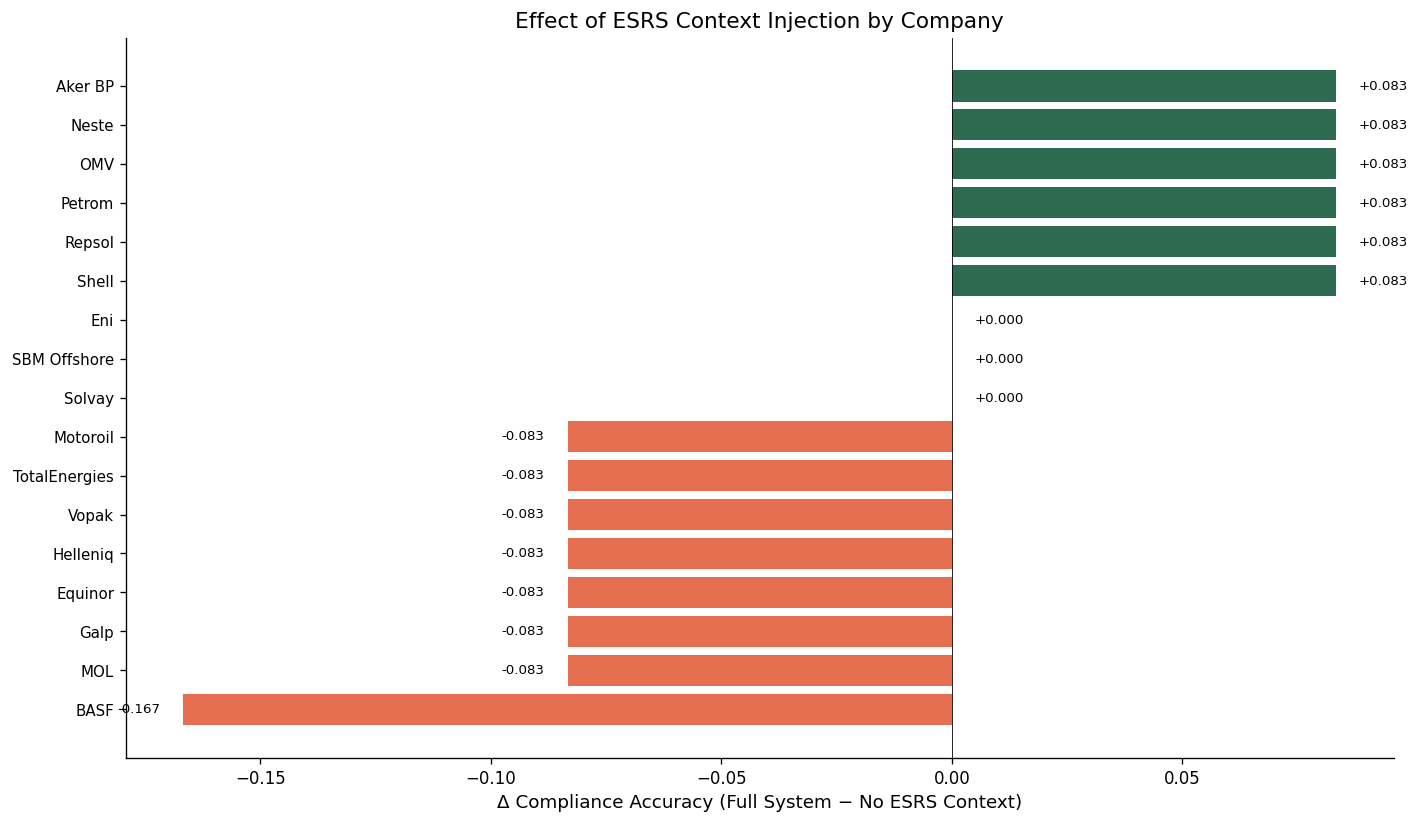

In [14]:
# Visualize per-company compliance accuracy delta
fig, ax = plt.subplots(figsize=(12, 7))

companies = df_per_co["Company"].tolist()
deltas = df_per_co["Δ Compl. Acc"].tolist()

# Sort by delta for better visualization
sorted_pairs = sorted(zip(companies, deltas), key=lambda x: x[1], reverse=True)
companies_sorted = [p[0] for p in sorted_pairs]
deltas_sorted = [p[1] for p in sorted_pairs]
colors = ["#2D6A4F" if d > 0 else ("#E76F51" if d < 0 else "#999999") for d in deltas_sorted]

y = np.arange(len(companies_sorted))
ax.barh(y, deltas_sorted, color=colors)
ax.set_yticks(y)
ax.set_yticklabels(companies_sorted, fontsize=9)
ax.set_xlabel("Δ Compliance Accuracy (Full System − No ESRS Context)")
ax.set_title("Effect of ESRS Context Injection by Company")
ax.axvline(x=0, color="black", linewidth=0.5)
ax.invert_yaxis()
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

# Add value labels
for i, v in enumerate(deltas_sorted):
    ax.text(v + 0.005 if v >= 0 else v - 0.005, i,
            f"{v:+.3f}", va="center", ha="left" if v >= 0 else "right", fontsize=8)

plt.tight_layout()
plt.savefig(PROJECT_ROOT / "data" / "artifacts" / "evaluation_results" / "rq2" / "rq2_per_company.png",
            dpi=150, bbox_inches="tight")
plt.show()

## 10. Compliance Level Confusion Matrices

Confusion matrices show whether errors are systematic (e.g., consistently overestimating as High) or random. One matrix per condition.

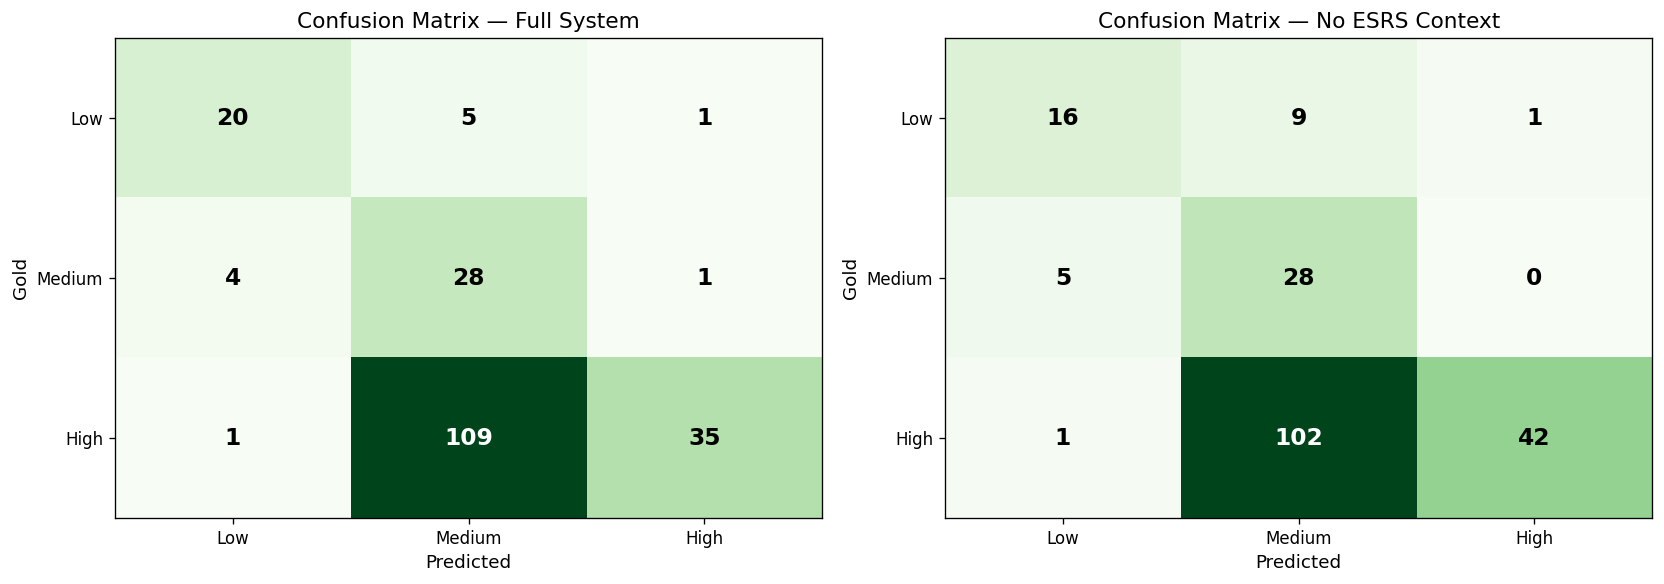

In [15]:
from collections import Counter

level_order = ["Low", "Medium", "High"]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, condition in zip(axes, CONDITIONS):
    # Build confusion matrix
    cm = np.zeros((3, 3), dtype=int)
    for r in results_by_condition[condition]:
        gold_idx = level_order.index(r.gold_level) if r.gold_level in level_order else -1
        pred_idx = level_order.index(r.predicted_level) if r.predicted_level in level_order else -1
        if gold_idx >= 0 and pred_idx >= 0:
            cm[gold_idx][pred_idx] += 1

    # Plot
    im = ax.imshow(cm, cmap="Greens", aspect="auto")
    ax.set_xticks(range(3))
    ax.set_yticks(range(3))
    ax.set_xticklabels(level_order)
    ax.set_yticklabels(level_order)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Gold")
    
    title = "Full System" if condition == "full_system" else "No ESRS Context"
    ax.set_title(f"Confusion Matrix — {title}")

    # Add count labels
    for i in range(3):
        for j in range(3):
            color = "white" if cm[i][j] > cm.max() * 0.6 else "black"
            ax.text(j, i, str(cm[i][j]), ha="center", va="center",
                    fontsize=14, fontweight="bold", color=color)

plt.tight_layout()
plt.savefig(PROJECT_ROOT / "data" / "artifacts" / "evaluation_results" / "rq2" / "rq2_confusion_matrices.png",
            dpi=150, bbox_inches="tight")
plt.show()

## 11. Detailed Per-Sample Results

Export full per-sample results for potential further analysis. Identify samples where the two conditions disagree the most.

In [16]:
# Build paired comparison: samples where conditions disagree on compliance level
disagreements = []
full_by_key = {(r.question_id, r.company): r for r in results_by_condition["full_system"]}
no_esrs_by_key = {(r.question_id, r.company): r for r in results_by_condition["no_esrs_context"]}

for key in full_by_key:
    full_r = full_by_key[key]
    no_esrs_r = no_esrs_by_key.get(key)
    if no_esrs_r is None:
        continue
    if full_r.predicted_level != no_esrs_r.predicted_level:
        disagreements.append({
            "Question": key[0],
            "Company": key[1],
            "ESRS": full_r.esrs_standard,
            "Gold": full_r.gold_level,
            "Full System": full_r.predicted_level,
            "No ESRS": no_esrs_r.predicted_level,
            "Full Correct": full_r.predicted_level == full_r.gold_level,
            "No ESRS Correct": no_esrs_r.predicted_level == no_esrs_r.gold_level,
        })

df_disagree = pd.DataFrame(disagreements)
n_disagree = len(df_disagree)
n_total_pairs = len(full_by_key)
print(f"Samples where conditions disagree: {n_disagree}/{n_total_pairs} ({100*n_disagree/max(n_total_pairs,1):.1f}%)")

if not df_disagree.empty:
    full_wins = df_disagree["Full Correct"].sum()
    no_esrs_wins = df_disagree["No ESRS Correct"].sum()
    neither = n_disagree - full_wins - no_esrs_wins
    print(f"  Full system correct: {full_wins}")
    print(f"  No ESRS correct:    {no_esrs_wins}")
    print(f"  Neither correct:    {neither}")
    print(f"\nDisagreement details:")
    print(df_disagree.to_string(index=False))

Samples where conditions disagree: 37/204 (18.1%)
  Full system correct: 17
  No ESRS correct:    20
  Neither correct:    0

Disagreement details:
Question       Company    ESRS   Gold Full System No ESRS  Full Correct  No ESRS Correct
      Q1          Galp  ESRS 1   High        High  Medium          True            False
      Q2           OMV  ESRS 2   High        High  Medium          True            False
      Q2 TotalEnergies  ESRS 2   High        High  Medium          True            False
      Q3           Eni ESRS E1   High      Medium    High         False             True
      Q3      Helleniq ESRS E1 Medium        High  Medium         False             True
      Q3        Repsol ESRS E1   High      Medium    High         False             True
      Q3        Solvay ESRS E1   High        High  Medium          True            False
      Q3 TotalEnergies ESRS E1   High      Medium    High         False             True
      Q4          Galp ESRS E2 Medium      Medium  

## 12. Save Results

Persist all results for thesis reporting.

In [17]:
from rag.config.settings import ARTIFACTS_DIR

rq2_dir = ARTIFACTS_DIR / "evaluation_results" / "rq2"
rq2_dir.mkdir(parents=True, exist_ok=True)

# Save per-sample results
for condition in CONDITIONS:
    rows = []
    for s in results_by_condition[condition]:
        rows.append({
            "question_id": s.question_id,
            "company": s.company,
            "esrs_standard": s.esrs_standard,
            "condition": s.condition,
            "predicted_level": s.predicted_level,
            "gold_level": s.gold_level,
            "compliance_acc": s.compliance_acc,
            "off_by_one_acc": s.off_by_one_acc,
            "token_f1_score": s.token_f1_score,
            "token_precision": s.token_precision,
            "token_recall": s.token_recall,
            "faithfulness": s.faithfulness,
        })
    path = rq2_dir / f"rq2_per_sample_{condition}.json"
    path.write_text(json.dumps(rows, indent=2), encoding="utf-8")
    print(f"Saved {len(rows)} sample results to {path.name}")

# Save aggregate results
agg_payload = {c: asdict(aggregates[c]) for c in CONDITIONS}
agg_path = rq2_dir / "rq2_aggregate_results.json"
agg_path.write_text(json.dumps(agg_payload, indent=2), encoding="utf-8")
print(f"Saved aggregate results to {agg_path.name}")

# Save per-standard table as CSV
csv_path = rq2_dir / "rq2_per_standard_comparison.csv"
df_per_std.drop(columns=["_delta_acc"], errors="ignore").to_csv(csv_path, index=False)
print(f"Saved per-standard table to {csv_path.name}")

# Save per-company table as CSV
csv_path_co = rq2_dir / "rq2_per_company_comparison.csv"
df_per_co.to_csv(csv_path_co, index=False)
print(f"Saved per-company table to {csv_path_co.name}")

# Save disagreements
if not df_disagree.empty:
    dis_path = rq2_dir / "rq2_disagreements.csv"
    df_disagree.to_csv(dis_path, index=False)
    print(f"Saved {len(df_disagree)} disagreements to {dis_path.name}")

print(f"\nAll RQ2 results saved to {rq2_dir}")

Saved 204 sample results to rq2_per_sample_full_system.json
Saved 204 sample results to rq2_per_sample_no_esrs_context.json
Saved aggregate results to rq2_aggregate_results.json
Saved per-standard table to rq2_per_standard_comparison.csv
Saved per-company table to rq2_per_company_comparison.csv
Saved 37 disagreements to rq2_disagreements.csv

All RQ2 results saved to /Users/sinahaghgoo/Library/CloudStorage/OneDrive-Persönlich/Master Thesis/Thesis Coding Part/ESRS-Regulation-Bot/data/artifacts/evaluation_results/rq2


## 13. Interpretation

### Summary of Findings

In [18]:
# Programmatic interpretation
full = aggregates["full_system"]
no_esrs = aggregates["no_esrs_context"]

delta_comp = full.compliance_accuracy - no_esrs.compliance_accuracy
delta_obo = full.off_by_one_accuracy - no_esrs.off_by_one_accuracy
delta_f1 = full.token_f1 - no_esrs.token_f1
delta_faith = full.faithfulness - no_esrs.faithfulness

print("RQ2 INTERPRETATION")
print("=" * 70)
print()

# Overall direction
improved_metrics = sum(1 for d in [delta_comp, delta_obo, delta_f1, delta_faith] if d > 0.001)
degraded_metrics = sum(1 for d in [delta_comp, delta_obo, delta_f1, delta_faith] if d < -0.001)

if improved_metrics > degraded_metrics:
    print(f"ESRS context injection IMPROVES results on {improved_metrics}/4 metrics.")
elif degraded_metrics > improved_metrics:
    print(f"ESRS context injection DEGRADES results on {degraded_metrics}/4 metrics.")
else:
    print(f"Results are MIXED: {improved_metrics} improved, {degraded_metrics} degraded.")

print()
print(f"Compliance accuracy:  {full.compliance_accuracy:.4f} vs {no_esrs.compliance_accuracy:.4f} (Δ = {delta_comp:+.4f})")
print(f"Off-by-one accuracy:  {full.off_by_one_accuracy:.4f} vs {no_esrs.off_by_one_accuracy:.4f} (Δ = {delta_obo:+.4f})")
print(f"Token F1:             {full.token_f1:.4f} vs {no_esrs.token_f1:.4f} (Δ = {delta_f1:+.4f})")
print(f"Faithfulness:         {full.faithfulness:.4f} vs {no_esrs.faithfulness:.4f} (Δ = {delta_faith:+.4f})")

print()
# Compliance accuracy is the primary metric
if delta_comp > 0.02:
    print("→ The primary metric (compliance accuracy) shows a clear improvement from")
    print("  ESRS context injection, validating the esrs_context module as a")
    print("  valuable component of the pipeline.")
elif delta_comp > 0:
    print("→ The primary metric (compliance accuracy) shows a modest improvement from")
    print("  ESRS context injection. The effect is positive but small.")
elif delta_comp < -0.02:
    print("→ The primary metric (compliance accuracy) is LOWER with ESRS context injection.")
    print("  This suggests the LLM's parametric knowledge may be sufficient, or that")
    print("  the injected context adds noise that interferes with compliance assessment.")
else:
    print("→ The primary metric (compliance accuracy) is essentially unchanged.")
    print("  ESRS context injection neither helps nor hurts compliance assessment.")

# Per-standard insights
print()
print("Per-standard highlights:")
for std in all_standards:
    full_acc = aggregates["full_system"].per_standard.get(std, {}).get("compliance_accuracy", 0)
    no_acc = aggregates["no_esrs_context"].per_standard.get(std, {}).get("compliance_accuracy", 0)
    d = full_acc - no_acc
    if abs(d) > 0.05:
        direction = "improves" if d > 0 else "degrades"
        print(f"  {std}: ESRS injection {direction} accuracy by {abs(d):.3f}")

RQ2 INTERPRETATION

ESRS context injection DEGRADES results on 2/4 metrics.

Compliance accuracy:  0.4069 vs 0.4216 (Δ = -0.0147)
Off-by-one accuracy:  0.9902 vs 0.9902 (Δ = +0.0000)
Token F1:             0.2838 vs 0.3400 (Δ = -0.0562)
Faithfulness:         0.9998 vs 1.0000 (Δ = -0.0002)

→ The primary metric (compliance accuracy) is essentially unchanged.
  ESRS context injection neither helps nor hurts compliance assessment.

Per-standard highlights:
  ESRS 1: ESRS injection improves accuracy by 0.059
  ESRS 2: ESRS injection improves accuracy by 0.118
  ESRS E1: ESRS injection degrades accuracy by 0.176
  ESRS E2: ESRS injection improves accuracy by 0.059
  ESRS E3: ESRS injection degrades accuracy by 0.118
  ESRS E4: ESRS injection degrades accuracy by 0.059
  ESRS G1: ESRS injection degrades accuracy by 0.235
  ESRS S1: ESRS injection degrades accuracy by 0.118
  ESRS S2: ESRS injection improves accuracy by 0.118
  ESRS S4: ESRS injection improves accuracy by 0.176


In [19]:
# Clean up Qdrant connection
try:
    qdrant.close()
except Exception:
    pass

print("Notebook complete.")

Notebook complete.
